In [34]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("telco_customer_churn.csv")
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [35]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
print(df.isnull().sum())
df = df.dropna(subset=["TotalCharges"])
df["Churn_Flag"] = (df["Churn"] == "Yes").astype(int)

churn_rate = df["Churn_Flag"].mean() * 100
print(f"Overall Churn Rate: {churn_rate:.2f}%")

customerID           0
gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64
Overall Churn Rate: 26.58%


Tenure_Cohort
0-12 months     47.68
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn_Flag, dtype: float64


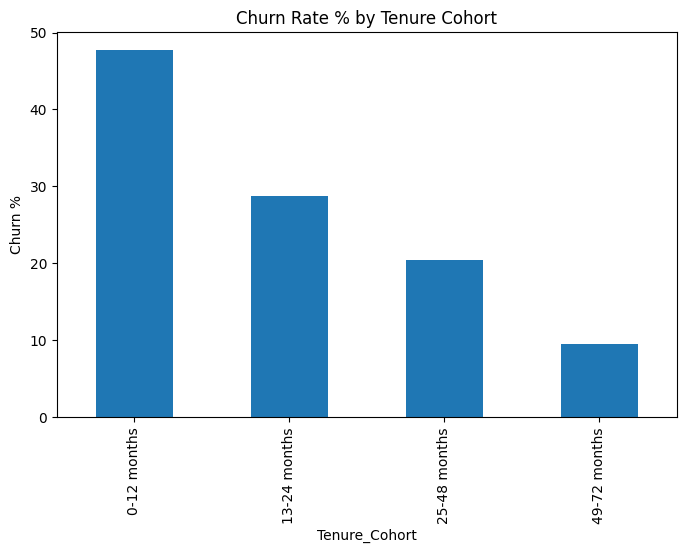

In [36]:
bins = [0, 12, 24, 48, 72]
labels = ["0-12 months", "13-24 months", "25-48 months", "49-72 months"]
df["Tenure_Cohort"] = pd.cut(df["tenure"], bins=bins, labels=labels, include_lowest=True)

cohort_churn = df.groupby("Tenure_Cohort", observed=True)["Churn_Flag"].mean() * 100
print(cohort_churn.round(2))

cohort_churn.plot(kind="bar", figsize=(8,5), title="Churn Rate % by Tenure Cohort")
plt.ylabel("Churn %")
plt.show()

Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn_Flag, dtype: float64


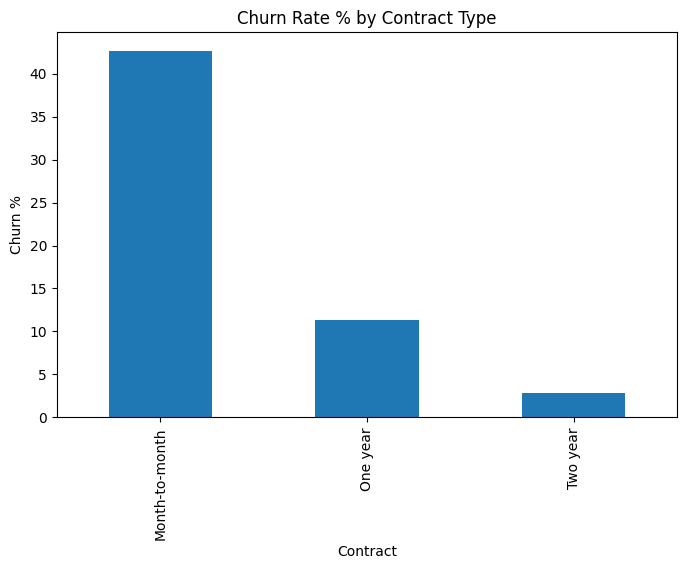

In [37]:
contract_churn = df.groupby("Contract")["Churn_Flag"].mean() * 100
print(contract_churn.round(2))

contract_churn.plot(kind="bar", figsize=(8,5), title="Churn Rate % by Contract Type")
plt.ylabel("Churn %")
plt.show()

In [38]:
print((df.groupby("PaymentMethod")["Churn_Flag"].mean() * 100).round(2))
print((df.groupby("InternetService")["Churn_Flag"].mean() * 100).round(2))

PaymentMethod
Bank transfer (automatic)    16.73
Credit card (automatic)      15.25
Electronic check             45.29
Mailed check                 19.20
Name: Churn_Flag, dtype: float64
InternetService
DSL            19.00
Fiber optic    41.89
No              7.43
Name: Churn_Flag, dtype: float64


In [39]:
risk = df[(df["InternetService"] == "Fiber optic") & (df["TechSupport"] == "No")]
print("High-risk segment churn %:", round(risk["Churn_Flag"].mean() * 100, 2))
print("Customers in segment:", len(risk))

High-risk segment churn %: 49.37
Customers in segment: 2230


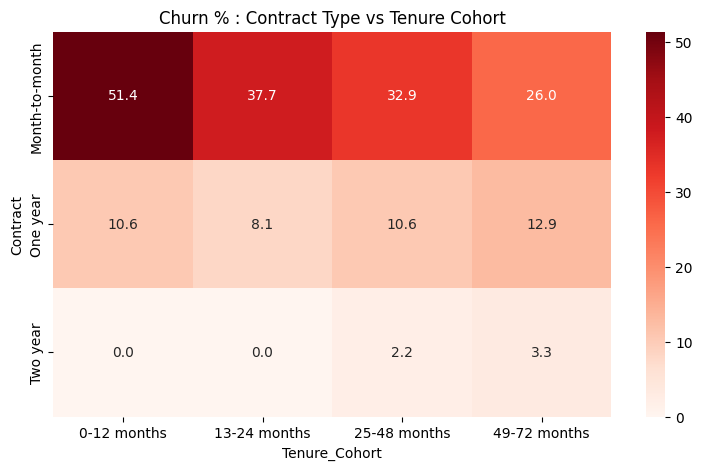

In [40]:
heat = df.pivot_table(index="Contract", columns="Tenure_Cohort",
                      values="Churn_Flag", aggfunc="mean", observed=True) * 100

plt.figure(figsize=(9,5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds")
plt.title("Churn % : Contract Type vs Tenure Cohort")
plt.show()

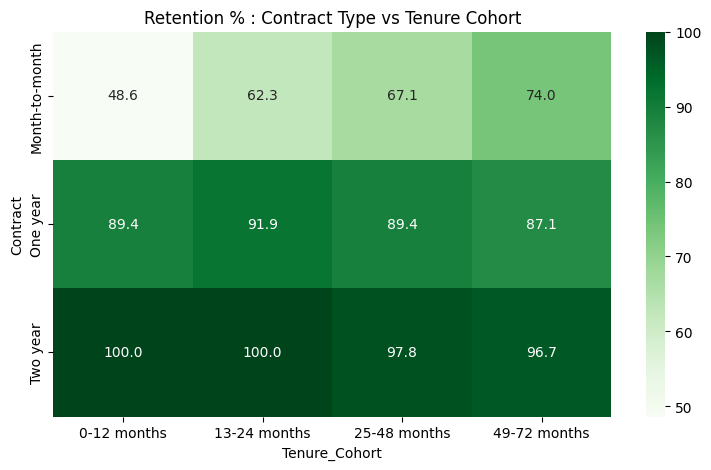

In [41]:
retention = 100 - heat
plt.figure(figsize=(9,5))
sns.heatmap(retention, annot=True, fmt=".1f", cmap="Greens")
plt.title("Retention % : Contract Type vs Tenure Cohort")
plt.show()

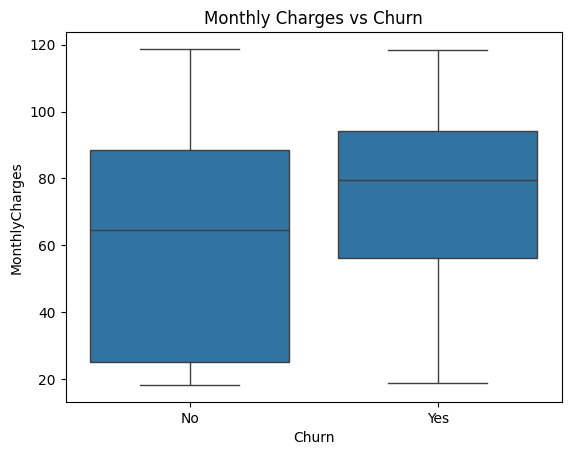

In [42]:
sns.boxplot(data=df, x="Churn", y="MonthlyCharges")
plt.title("Monthly Charges vs Churn")
plt.show()

In [43]:
print("Tenure cohort churn %")
print((df.groupby("Tenure_Cohort", observed=True)["Churn_Flag"].mean() * 100).round(2))
print("\nContract churn %")
print((df.groupby("Contract")["Churn_Flag"].mean() * 100).round(2))
print("\nMedian Monthly Charges")
print(df.groupby("Churn")["MonthlyCharges"].median().round(2))

Tenure cohort churn %
Tenure_Cohort
0-12 months     47.68
13-24 months    28.71
25-48 months    20.39
49-72 months     9.51
Name: Churn_Flag, dtype: float64

Contract churn %
Contract
Month-to-month    42.71
One year          11.28
Two year           2.85
Name: Churn_Flag, dtype: float64

Median Monthly Charges
Churn
No     64.45
Yes    79.65
Name: MonthlyCharges, dtype: float64


# Customer Cohort & Churn Analytics
Analysis of the IBM Telco Churn dataset using tenure cohorts, contract types, a churn heatmap and a retention matrix.

## Churn Analysis Report

**Data preparation:** 11 rows with blank TotalCharges values were removed, leaving 7,032 customers.

**Baseline churn rate:** 26.58%

### Key Findings
1. **Tenure:** Customers in the 0-12 month cohort churn at 47.68%, compared to 28.71% (13-24 months), 20.39% (25-48 months) and just 9.51% (49-72 months). Churn falls steadily as tenure grows, so new customers are the most likely to leave.
2. **Contract type:** Month-to-month contracts show 42.71% churn, versus 11.28% for one-year and 2.85% for two-year contracts.
3. **High-risk segment:** Fiber optic customers without Tech Support churn at 49.37% (2,230 customers), almost double the baseline rate.
4. **Payment method:** Electronic check users churn at 45.29%, far above automatic bank transfer (16.73%) and automatic credit card (15.25%).
5. **Internet service:** Fiber optic customers churn at 41.89%, compared to 19.00% for DSL and 7.43% for customers without internet service.
6. **Monthly charges:** The median monthly charge for churned customers is 79.65, compared to 64.45 for retained customers, so higher-paying customers are more likely to leave.

### Strategic Retention Recommendations
1. Offer onboarding support and loyalty incentives during the first 12 months, when churn is highest (47.68%).
2. Encourage month-to-month customers to move to one-year or two-year contracts through discounts.
3. Bundle free or discounted Tech Support with Fiber optic plans to reduce churn in the highest-risk segment.
4. Incentivize electronic check users to switch to automatic payments.
5. Investigate Fiber optic service quality and pricing, since its churn is more than double that of DSL.
6. Review pricing and offer personalized plans to customers with high monthly charges.